# This is the report template for the Assignment in CSCU9M3 Autumn 2026

## Follow these instructions:
- Save this file in the form: __ZZZZZZZ_M3_Aut26_TheAssignment.ipynb__ where __ZZZZZZZ__ is your student number
- Fill in the report 
 * Use a mix of code and markdown cells to tell a data-story, only the *Executive Summary* should be contained in a single markdown cell
 * all other sections should have multiple cells and outputs, where you explain what you are doing and why.
- When you are finished then ...
 * Save the file
 * Restart the Kernel and re-run the whole notebook. "Kernel" -> "Restart & Run" in the menu at top
 * Make sure everything has executed as expected. If cells run with error that you want to keep to show your attempt, then manually run every cell below the faulty one to show the output.
 * Make sure no __Markdown__ cell is in *edit* mode
 * Save file again
 * Delete this cell and remove any instructions from the template (except headings)
 * __Download this notebook as HTML__, you do that under *File->Download as-> HTML*
   + make sure to use the same name format, just different extension
 * __Upload the html file__ to the assessment on Canvas and submit

## Executive Summary
Write a short (200 words max) summary of what the report contains and what you have discovered.

## Introduction
The World Bank's *Gender Statistics* database contains **991 indicators** for **265 economies** back to 1960.
It covers paid work, education, health, fertility, legal rights, financial inclusion and political
representation, and most indicators are published separately for women and for men.

I chose it for three reasons. Almost every indicator has a **female and a male version**, so the natural
unit of analysis is the *gap between women and men inside a country*. The data are a **panel**, so I can
study change over time rather than a single snapshot. And the topic is a global policy target: gender
equality is United Nations Sustainable Development Goal 5.

Going in, I expected gender gaps to be closing steadily as countries became richer and better educated, and
I suspected that girls' education would be the force closing the labour market gap. The report shows that
the first expectation is only partly true, and that the second is not supported by the data at all.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Data Cleaning
The zip file contains six CSV files. This notebook uses three of them:

| File | What it is | Why I need it |
|---|---|---|
| `Gender_StatsData.csv` | 262,615 rows of indicator values, one column per year (1960–2021) | the data itself |
| `Gender_StatsCountry.csv` | one row per economy: name, region, income group | to group countries and to spot regional aggregates |
| `Gender_StatsSeries.csv` | one row per indicator: definition, unit, source | to document the indicators |

The other three files (`...FootNote`, `...Country-Series`, `...Series-Time`) only contain notes about
where individual numbers came from. They are unuseful for the analysis, so I do not load them.

In [2]:
# a cheap look at the raw file (first 5 rows, all columns)
raw_peek = pd.read_csv("Gender_StatsData.csv", nrows=5)
print("Columns in the file:", raw_peek.shape[1])
raw_peek.iloc[0:4, 0:12]

Columns in the file: 67


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,1966,1967
0,Africa Eastern and Southern,AFE,A woman can apply for a passport in the same w...,SG.APL.PSPT.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,A woman can be head of household in the same w...,SG.HLD.HEAD.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Africa Eastern and Southern,AFE,A woman can choose where to live in the same w...,SG.LOC.LIVE.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Eastern and Southern,AFE,A woman can get a job in the same way as a man...,SG.GET.JOBS.EQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The layout is now clear: the first 4 columns identify *who* (country) and *what* (indicator), and the
remaining 62 columns are years, with one empty artefact column at the very end. Each row is therefore one (country, indicator) pair, and the years run
across the row. It's a **wide** layout, and is difficulty for analysis, because adding a new year means adding a new column and every calculation has to be repeated once per year.

follow from the raw_peek I make a practical decision **only keep the years 1990–2021.** The file has 67 columns. Before 1990 most of the modern indicators are empty, I only needs the years 1990–2021 and the four identifier columns It makes pandas read only 36 columns, which keeps the notebook fast and the memory use modest.

In [3]:
YEARS = [str(year) for year in range(1990, 2022)]   
ID_COLUMNS = ["Country Name", "Country Code", "Indicator Name", "Indicator Code"]

raw = pd.read_csv("Gender_StatsData.csv", usecols=ID_COLUMNS + YEARS)

print("Shape of the subset:", raw.shape)
print("Countries in the file:", raw["Country Code"].nunique())  #sum number of diffierent rows, avoid repetition
print("Indicators in the file:", raw["Indicator Code"].nunique())
raw.head(3)

Shape of the subset: (262615, 36)
Countries in the file: 265
Indicators in the file: 991


,Country Name,Country Code,Indicator Name,Indicator Code,1990,1991,1992,1993,1994,1995,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Africa Eastern and Southern,AFE,A woman can apply for a passport in the same w...,SG.APL.PSPT.EQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,A woman can be head of household in the same w...,SG.HLD.HEAD.EQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Africa Eastern and Southern,AFE,A woman can choose where to live in the same w...,SG.LOC.LIVE.EQ,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# only keep the two chosen indicators
INDICATORS = {    
"SL.TLF.CACT.FE.ZS": "Female labour force participation (% of women aged 15+)",    
"SL.TLF.CACT.MA.ZS": "Male labour force participation (% of men aged 15+)",
}
subset = raw[raw["Indicator Code"].isin(INDICATORS.keys())].copy()

print("Shape after filtering:", subset.shape)
print(subset["Indicator Code"].value_counts())

Shape after filtering: (530, 36)
Indicator Code
SL.TLF.CACT.FE.ZS    265
SL.TLF.CACT.MA.ZS    265
Name: count, dtype: int64


In [5]:
# reshape from wide to long format
long = subset.melt(
    id_vars=["Country Code", "Indicator Code"],   
    value_vars=YEARS,   # turn columns into rows
    var_name="Year",
    value_name="Value",
)
long["Year"] = long["Year"].astype(int)  #string to int
long["Value"] = pd.to_numeric(long["Value"], errors="coerce") 
long = long.dropna(subset=["Value"])  #delete empty value

print("Long shape:", long.shape)
long.head()

Long shape: (15040, 4)


,Country Code,Indicator Code,Year,Value
0,AFE,SL.TLF.CACT.FE.ZS,1990,64.888276
1,AFE,SL.TLF.CACT.MA.ZS,1990,80.220056
2,AFW,SL.TLF.CACT.FE.ZS,1990,60.038278
3,AFW,SL.TLF.CACT.MA.ZS,1990,72.574196
4,ARB,SL.TLF.CACT.FE.ZS,1990,19.427845


The next problem is **mixed units of observation**. The World Bank file places real countries and
aggregates such as "World", "Euro area" or "Sub-Saharan Africa" (which is an average of 48 countries) in
the same column. Averaging them together would double-count some countries and produce nonsense.

The country file gives a clean way to separate them: aggregates have **no region** ("Sub-Saharan Africa" is
in no region), while every real country belongs to one of seven regions. So I merge the metadata in and
drop the rows without a region. The same merge also brings in the *income group*, which I use later for
one of the descriptive questions.

In [6]:
#remove regional aggregates
country = pd.read_csv("Gender_StatsCountry.csv",
                      usecols=["Country Code", "Short Name", "Region", "Income Group"])
print("economies in the country file:", len(country))

long = long.merge(country, on="Country Code", how="left")

# economies with no region are averages, not countries
aggregates = country.loc[country["Region"].isna(), "Country Code"].tolist()
print("regional averages to remove:", len(aggregates))

long = long[~long["Country Code"].isin(aggregates)]
print("rows left:", len(long), "| countries left:", long["Country Code"].nunique())

economies in the country file: 265
regional averages to remove: 48
rows left: 11968 | countries left: 187


In [7]:
# one row per country and year, plus the gap

data = long.pivot_table(index=["Country Code", "Year"],
                        columns="Indicator Code",
                        values="Value").reset_index()

data = data.merge(country, on="Country Code", how="left")

# men's rate minus women's rate 
data["LFPR_gap"] = data["SL.TLF.CACT.MA.ZS"] - data["SL.TLF.CACT.FE.ZS"]

print("shape:", data.shape)
data.dropna(subset=["LFPR_gap"]).head()      # only rows that really have data

shape: (5984, 8)


,Country Code,Year,SL.TLF.CACT.FE.ZS,SL.TLF.CACT.MA.ZS,Short Name,Region,Income Group,LFPR_gap
0,AFG,1990,15.180,77.430000,Afghanistan,South Asia,Low income,62.250000
1,AFG,1991,15.214,77.176003,Afghanistan,South Asia,Low income,61.962003
2,AFG,1992,15.223,76.871002,Afghanistan,South Asia,Low income,61.648003
3,AFG,1993,15.197,76.580002,Afghanistan,South Asia,Low income,61.383002
4,AFG,1994,15.178,76.330002,Afghanistan,South Asia,Low income,61.152001


## Exploratory Data Analysis
Programmatically explore the dataset. Tell the reader, how the dataset looks like and at least three most interesting observations that you can learn from the data.

### Observation 1 — men's participation is high everywhere, women's is not

In 2019 women are in the labour force 51.4% of the time on average, men 70.9%. Men are in work almost
everywhere; the big differences between countries are all on the women's side.

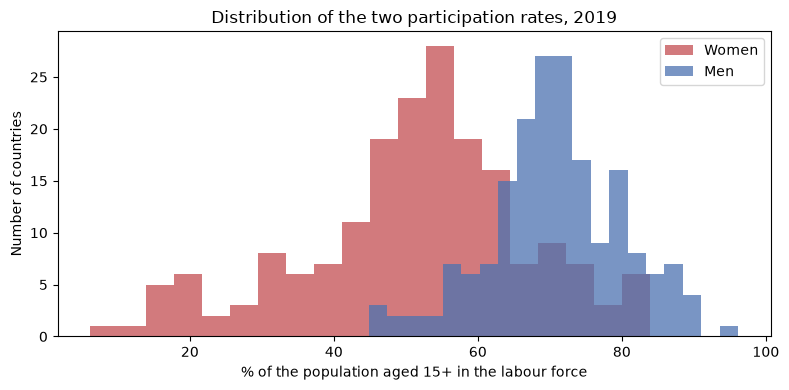

women: mean 51.4 %
men: mean 70.9 %


In [8]:
#the distribution of the two rates in 2019
data_2019 = data[data["Year"] == 2019].copy()
fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(data_2019["SL.TLF.CACT.FE.ZS"], bins=20, color="#c44e52", alpha=0.75, label="Women")
ax.hist(data_2019["SL.TLF.CACT.MA.ZS"], bins=20, color="#4c72b0", alpha=0.75, label="Men")

ax.set_title("Distribution of the two participation rates, 2019")
ax.set_xlabel("% of the population aged 15+ in the labour force")
ax.set_ylabel("Number of countries")
ax.legend()
plt.tight_layout()
plt.show()
print("women: mean",round(data_2019["SL.TLF.CACT.FE.ZS"].mean(),1),"%")
print("men: mean",round(data_2019["SL.TLF.CACT.MA.ZS"].mean(),1),"%")

### Observation 2 — the global work gap is closing, but mostly because men's participation is falling

The world average gap fell from 26.7 points in 1990 to 19.5 points in 2019. The surprise is how it fell.
Women's participation barely moved (48.9% → 51.4%, +2.5 points), while men's participation fell by almost
twice as much (75.6% → 70.9%, −4.7 points). About **two thirds** of the improvement therefore comes from
men leaving the labour force, not from women entering it. The dip at the end of both lines is the first year
of COVID-19, which pulled both rates down and left the gap almost unchanged.

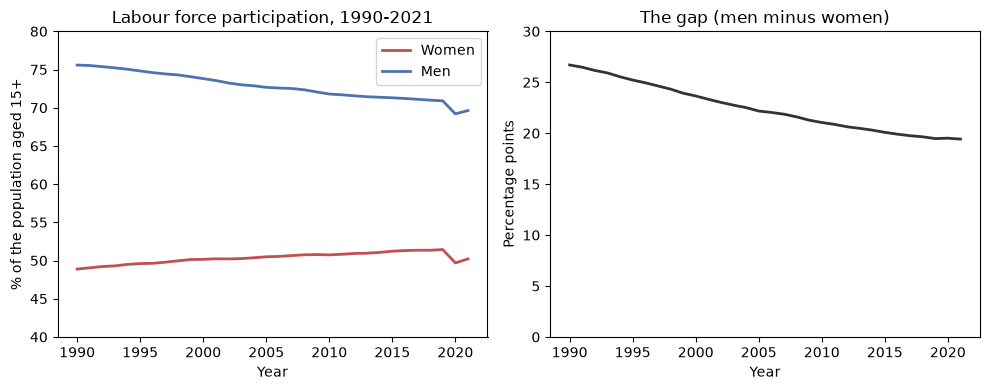

1990 -> 2019, women: 2.55 points
1990 -> 2019, men:   -4.68 points


In [9]:
global_trend = data.groupby("Year")[["SL.TLF.CACT.FE.ZS", "SL.TLF.CACT.MA.ZS", "LFPR_gap"]].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# left: the two rates over time
ax1.plot(global_trend.index, global_trend["SL.TLF.CACT.FE.ZS"], color="#c44e52", linewidth=2, label="Women")
ax1.plot(global_trend.index, global_trend["SL.TLF.CACT.MA.ZS"], color="#4c72b0", linewidth=2, label="Men")
ax1.set_title("Labour force participation, 1990-2021")
ax1.set_xlabel("Year")
ax1.set_ylabel("% of the population aged 15+")
ax1.set_ylim(40, 80)
ax1.legend()

# right: the gap between them
ax2.plot(global_trend.index, global_trend["LFPR_gap"], color="#333333", linewidth=2)
ax2.set_title("The gap (men minus women)")
ax2.set_xlabel("Year")
ax2.set_ylabel("Percentage points")
ax2.set_ylim(0, 30)

plt.tight_layout()
plt.show()

# how much of the change came from women and how much from men?
change_women = global_trend.loc[2019, "SL.TLF.CACT.FE.ZS"] - global_trend.loc[1990, "SL.TLF.CACT.FE.ZS"]
change_men = global_trend.loc[2019, "SL.TLF.CACT.MA.ZS"] - global_trend.loc[1990, "SL.TLF.CACT.MA.ZS"]
print("1990 -> 2019, women:", round(change_women, 2), "points")
print("1990 -> 2019, men:  ", round(change_men, 2), "points")

### Observation 3 — the gap exists in almost every country

The histogram shows how the gap is spread across countries in 1990 and in 2019. Almost all the bars are to
the right of zero: in **183 of the 187 countries** in 2019, more men than women are in the labour force. Only
four countries have a negative gap (Burundi, Rwanda, Guinea and Sierra Leone), and in all four the difference
is smaller than 2.5 points. The whole distribution moved left since 1990 — the median gap fell from 23.5 to
15.6 points — but the shape is the same. A gender gap in paid work is the normal case, not the exception.

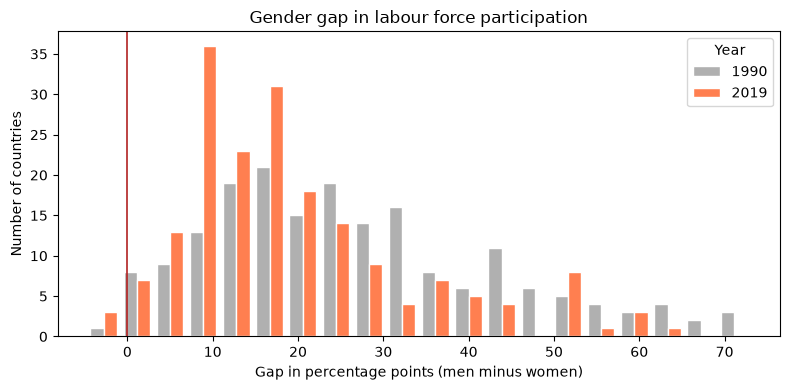

countries with data in 2019: 187
countries where women work more than men: 4
median gap 1990: 23.5 points
median gap 2019: 15.6 points


In [10]:
#the distribution of the gap, 1990 vs 2019
gap_1990 = data.loc[data["Year"] == 1990, "LFPR_gap"].dropna()
gap_2019 = data.loc[data["Year"] == 2019, "LFPR_gap"].dropna()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist([gap_1990, gap_2019], bins=20, color=["#b0b0b0", "#FF7F50"],
        label=["1990", "2019"], edgecolor="white")
ax.axvline(0, color="#B22222", linewidth=1.2)      # the line "no gap"

ax.set_title("Gender gap in labour force participation")
ax.set_xlabel("Gap in percentage points (men minus women)")
ax.set_ylabel("Number of countries")
ax.legend(title="Year")
plt.tight_layout()
plt.show()

print("countries with data in 2019:", len(gap_2019))
print("countries where women work more than men:", (gap_2019 < 0).sum())
print("median gap 1990:", round(gap_1990.median(), 1), "points")
print("median gap 2019:", round(gap_2019.median(), 1), "points")

## Descriptive Analytics

Descriptive analytics describes what is in the data without explaining why. Every number in this section is a mean, a count, a rank or a plain correlation over the panel built above; nothing here fits a model or makes a causal claim.

Two rules keep the answers comparable. I use **2019 as the reference year**: 2020 and 2021 are the first two years of COVID-19, and Observation 2 shows the pandemic pulled both rates down and left the gap almost unchanged, so it is a poor year to end a twenty-nine year comparison on. I report 2021 next to 1990 and 2019 wherever the direction of change matters, so that the pandemic is visible rather than silently absorbed.

The three questions are:

1. **Regional** — is the gap the same in every region, and which region has narrowed fastest?
2. **Income** — does the gap shrink as a country gets richer?
3. **Convergence** — did the countries with the biggest gaps in 1990 close them by 2019?

The first two split the same panel by a variable that is already in the metadata; the third follows individual countries through time.

### Question 1 — Is the gap the same in every region?

**The question.** In 2019, how large is the gap in labour force participation in each of the seven regions, how far apart are they, and which region has narrowed fastest since 1990?

**Why it is interesting.** Everything so far has been a world average, and a world average is a claim about a typical country that may describe no country at all. Region is the cheapest available split — one column in the metadata — and it carries real institutional content, because labour markets, schooling and childcare are organised regionally rather than nationally. If the gap turns out to be concentrated in two or three regions, the global figure is the wrong number to put in front of a policy maker, and the "closing everywhere" reading of Observation 2 needs qualifying.

In [11]:
# gap by region: level in 1990, 2019 and 2021, the change, and how many countries each average covers
region_gap = data.pivot_table(index="Region", columns="Year", values="LFPR_gap")[[1990, 2019, 2021]]
region_gap["change_1990_2019"] = (region_gap[2019] - region_gap[1990]).round(1)
region_gap["pct_change"] = ((region_gap[2019] / region_gap[1990] - 1) * 100).round(0)
region_gap["countries"] = data[data["Year"] == 2019].groupby("Region")["LFPR_gap"].count()

region_table = region_gap.round(1).sort_values(2019, ascending=False)
print("world average 2019:", round(data.loc[data["Year"] == 2019, "LFPR_gap"].mean(), 1), "points")
region_table

world average 2019: 19.5 points


Year,1990,2019,2021,change_1990_2019,pct_change,countries
Region,,,,,,
Middle East & North Africa,53.9,43.9,42.9,-10.0,-19.0,21
South Asia,46.7,36.7,36.6,-10.0,-21.0,8
Latin America & Caribbean,33.9,22.3,22.2,-11.6,-34.0,31
East Asia & Pacific,20.4,15.4,15.5,-5.0,-24.0,29
Europe & Central Asia,20.4,14.1,14.0,-6.2,-30.0,49
Sub-Saharan Africa,17.3,12.3,12.6,-5.0,-29.0,47
North America,18.0,10.0,10.1,-8.0,-44.0,2


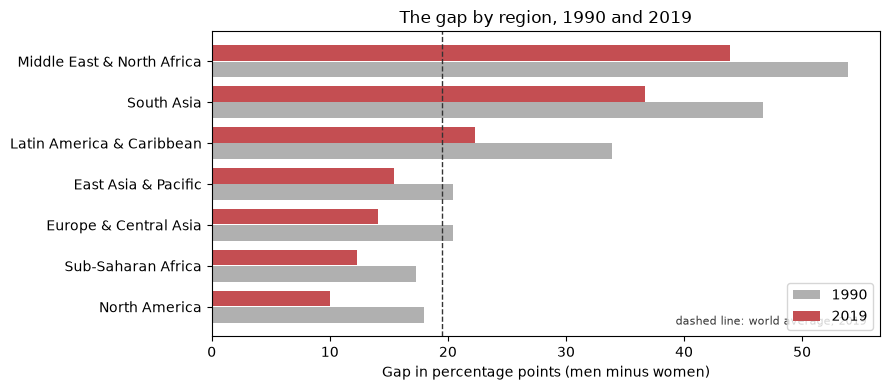

In [12]:
# the same numbers as a picture: 1990 against 2019, region by region
order = region_table.index
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(order))

ax.barh(y + 0.2, region_table.loc[order, 1990], height=0.38, color="#b0b0b0", label="1990")
ax.barh(y - 0.2, region_table.loc[order, 2019], height=0.38, color="#c44e52", label="2019")

world_2019 = data.loc[data["Year"] == 2019, "LFPR_gap"].mean()
ax.axvline(world_2019, color="#333333", linestyle="--", linewidth=1)
ax.text(0.98, 0.03, "dashed line: world average, 2019", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, color="#333333")

ax.set_yticks(y)
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.set_xlabel("Gap in percentage points (men minus women)")
ax.set_title("The gap by region, 1990 and 2019")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [13]:
# a regional average hides the countries inside it, so look inside the worst region
mena = data[(data["Year"] == 2019) & (data["Region"] == "Middle East & North Africa")].copy()
mena["gap"] = mena["LFPR_gap"].round(1)
print(f"MENA: {len(mena)} countries, gap from {mena['gap'].min():.1f} to {mena['gap'].max():.1f} points")
print(mena.sort_values("gap", ascending=False)[["Short Name", "gap"]].head(6).to_string(index=False))

south_asia = data[(data["Year"] == 2019) & (data["Region"] == "South Asia")].copy()
print(f"\nSouth Asia: {len(south_asia)} countries, gap from {south_asia['LFPR_gap'].min():.1f} "
      f"to {south_asia['LFPR_gap'].max():.1f} points")
print(south_asia.sort_values("LFPR_gap", ascending=False)[["Short Name", "LFPR_gap"]]
      .round(1).to_string(index=False))

MENA: 21 countries, gap from 8.0 to 62.0 points
          Short Name  gap
               Yemen 62.0
                Iraq 61.3
                Oman 58.6
Syrian Arab Republic 55.9
        Saudi Arabia 53.4
                Iran 53.2

South Asia: 8 countries, gap from 2.0 to 57.6 points
 Short Name  LFPR_gap
   Pakistan      57.6
      India      52.1
Afghanistan      50.3
 Bangladesh      43.7
  Sri Lanka      38.6
   Maldives      33.2
     Bhutan      15.9
      Nepal       2.0


**The answer.** The gap is not a global number with regional noise on top. It is two regions with a large gap and five with a small one.

In 2019 the average runs from **43.9 points in Middle East & North Africa** and **36.7 in South Asia** down to **15.4 in East Asia & Pacific, 14.1 in Europe & Central Asia, 12.3 in Sub-Saharan Africa and 10.0 in North America** (two countries). Latin America at 22.3 sits alone in the middle. The spread between top and bottom is **33.9 points**, wider than the world average itself, and only Latin America comes within three points of the world figure of 19.5.

The movement since 1990 is smaller than the level difference. The regions that narrowed most in absolute terms are the ones that started worst: Latin America (−11.6), MENA (−10.0) and South Asia (−10.0), against −5.0 for Sub-Saharan Africa and East Asia. MENA and South Asia therefore still sit **24.4 and 17.2 points above the world average**, and their falls are proportionally the smallest in the table (−19% and −21%). North America's 44% fall looks dramatic but starts from a small base and rests on two countries.

A region is also not a country, and the averages are not weighted by population. Inside MENA, Yemen (62.0) and Iraq (61.3) pull the average up while Israel sits at 8.0, a range of 54 points inside one "region". South Asia is worse: Pakistan (57.6) and India (52.1) against Nepal (2.0), with eight countries counting equally. So a regional mean is the start of a policy question, not an answer.

The 2021 column barely moves (MENA 42.9, world 19.4), which says COVID-19 did not break the regional pattern even though it lowered both rates.

### Question 2 — Does the gap shrink as a country gets richer?

**The question.** In 2019, how does the gap differ across the World Bank's four income groups — low, lower middle, upper middle and high — and how much has each group closed since 1990?

**Why it is interesting.** This is the assumption I stated in the introduction, turned into something a table can settle: that gender gaps close as countries become richer and better educated. Income group is the only development variable already in the country metadata, so testing it costs one more column in the merge. If the assumption holds, the gap should fall monotonically from low to high income, and the high-income group should have narrowed most.

In [14]:
# the same split, by income group
income_gap = data.pivot_table(index="Income Group", columns="Year", values="LFPR_gap")[[1990, 2019, 2021]]
income_gap["change_1990_2019"] = (income_gap[2019] - income_gap[1990]).round(1)
income_gap["pct_change"] = ((income_gap[2019] / income_gap[1990] - 1) * 100).round(0)
income_gap["median_2019"] = data[data["Year"] == 2019].groupby("Income Group")["LFPR_gap"].median()
income_gap["countries"] = data[data["Year"] == 2019].groupby("Income Group")["LFPR_gap"].count()

income_table = income_gap.round(1).sort_values(2019, ascending=False)
income_table

Year,1990,2019,2021,change_1990_2019,pct_change,median_2019,countries
Income Group,,,,,,,
Upper middle income,31.3,23.2,23.3,-8.1,-26.0,20.8,50
Lower middle income,26.2,21.8,21.6,-4.4,-17.0,16.9,48
High income,27.2,16.2,15.9,-11.0,-40.0,12.4,60
Low income,18.5,16.0,16.3,-2.6,-14.0,11.8,29


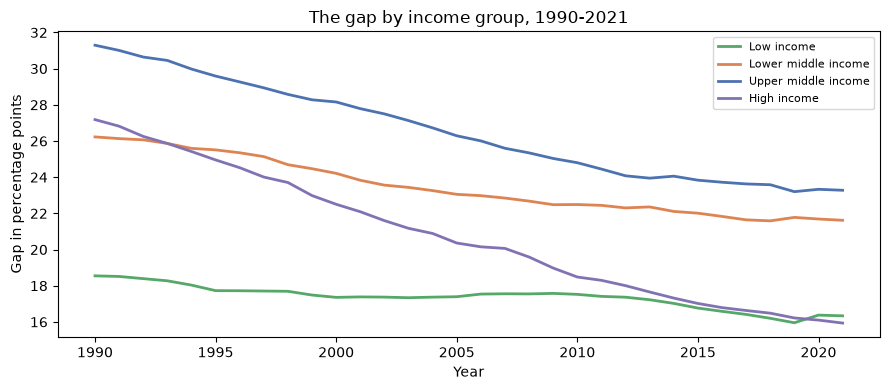

In [15]:
# the four groups year by year: does the ranking hold for the whole period?
income_series = data.groupby(["Year", "Income Group"])["LFPR_gap"].mean().unstack()
colours = {"Low income": "#55a868", "Lower middle income": "#dd8452",
           "Upper middle income": "#4c72b0", "High income": "#8172b3"}

fig, ax = plt.subplots(figsize=(9, 4))
for group in colours:
    ax.plot(income_series.index, income_series[group], color=colours[group],
            linewidth=2, label=group)

ax.set_xlabel("Year")
ax.set_ylabel("Gap in percentage points")
ax.set_title("The gap by income group, 1990-2021")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
# a second view of the same shape: how common is a big gap in each group?
big = data[data["Year"] == 2019].assign(above_20=lambda x: x["LFPR_gap"] > 20)
share = (big.groupby("Income Group")["above_20"].mean() * 100).round(0)

print("share of countries with a gap above 20 points in 2019:")
print(share.sort_values(ascending=False).to_string())

share of countries with a gap above 20 points in 2019:
Income Group
Upper middle income    54.0
Lower middle income    44.0
Low income             31.0
High income            17.0


**The answer.** No. The relationship is not a straight line down from poor to rich; it is humped, which inverts the assumption.

In 2019 the gap is **largest in the upper middle income group (23.2 points)** and the lower middle group (21.8), and **smaller at both ends — 16.2 for high income and 16.0 for low income**. The poorest countries in the panel have almost the same gap as the richest, and both middle groups are six to seven points wider. The same shape survives in the median (12.4 high income, 11.8 low income) and in the frequency of a big gap: **54% of upper middle income countries and 44% of lower middle income countries are above 20 points, against 31% of low income and 17% of high income countries.**

Change since 1990 has a different shape again. High income narrowed by **11.0 points (−40%)**, upper middle income by 8.1, lower middle income by 4.4, and low income by only **2.6 (−14%)**. The rich group has both the smallest gap and the fastest fall; the group that started lowest has hardly moved. The ranking is not fixed either: in 1990 high income was second (27.2, behind upper middle income at 31.3) and by 2019 it is third, having crossed below lower middle income.

A descriptive reading, not a causal one: the indicator counts *any* labour force participation, and in low income economies much of women's work is subsistence farming, water collection or family enterprise, which counts whether or not there is a wage attached. As an economy moves to middle income, work shifts out of the household into a market where the male-breadwinner norm and missing childcare keep women out; at high income, services, part-time work, education and childcare institutions have caught up. The hump is consistent with that story — but it is equally consistent with income groups being four very broad labels, which is why the continuous income measure and the hours-of-work data in the suggestions section are needed before believing it.

### Question 3 — Did the countries with the biggest gaps in 1990 close them?

**The question.** For the countries with data in both years, does the size of the gap in 1990 predict how much it changed by 2019 — did the worst offenders narrow fastest?

**Why it is interesting.** It is the cheapest test of whether the problem is self-correcting. If narrowing is proportional to the size of the gap, the gap erodes on its own and time does the policy work. If the change is unrelated to the starting point, a country with a 60-point gap stays there and the difference is permanent. Question 1 suggests the second is more likely, but that was a claim about regions; this asks the same question about individual countries.

In [17]:
# pair the 1990 gap with the 2019 gap, one row per country
pairs = (data.loc[data["Year"].isin([1990, 2019])]
         .pivot_table(index="Country Code", columns="Year", values="LFPR_gap")
         .dropna(subset=[1990, 2019]))
pairs.columns = ["gap_1990", "gap_2019"]
pairs["change"] = pairs["gap_2019"] - pairs["gap_1990"]

print("countries with data in both years:", len(pairs))
print("narrowed:", (pairs["change"] < 0).sum(), "| widened:", (pairs["change"] > 0).sum())
print("median change:", round(pairs["change"].median(), 1), "points")
print("correlation between the 1990 gap and the change:", round(pairs["gap_1990"].corr(pairs["change"]), 2))

slope, intercept = np.polyfit(pairs["gap_1990"], pairs["change"], 1)
print("line of best fit: change =", round(slope, 2), "* gap_1990 +", round(intercept, 2))

countries with data in both years: 187
narrowed: 142 | widened: 45
median change: -6.7 points
correlation between the 1990 gap and the change: -0.56
line of best fit: change = -0.28 * gap_1990 + 0.33


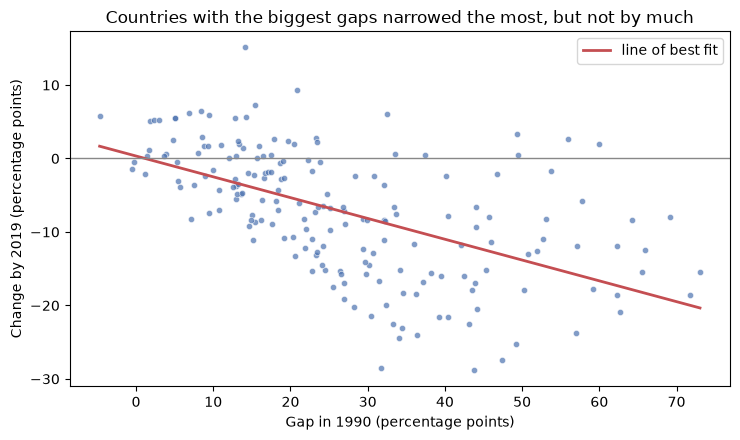

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(pairs["gap_1990"], pairs["change"], s=20, color="#4c72b0",
           alpha=0.7, edgecolor="white", linewidth=0.5)

x = np.linspace(pairs["gap_1990"].min(), pairs["gap_1990"].max(), 100)
ax.plot(x, slope * x + intercept, color="#c44e52", linewidth=2, label="line of best fit")
ax.axhline(0, color="#888888", linewidth=1)

ax.set_xlabel("Gap in 1990 (percentage points)")
ax.set_ylabel("Change by 2019 (percentage points)")
ax.set_title("Countries with the biggest gaps narrowed the most, but not by much")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# what the slope means in practice: the ten worst and the ten best starting points
worst_1990 = pairs.sort_values("gap_1990", ascending=False).head(10)
best_1990 = pairs.sort_values("gap_1990").head(10)

print(f"ten biggest gaps in 1990:  {worst_1990['gap_1990'].mean():.1f} -> {worst_1990['gap_2019'].mean():.1f} "
      f"(mean change {worst_1990['change'].mean():.1f})")
print(f"ten smallest gaps in 1990: {best_1990['gap_1990'].mean():.1f} -> {best_1990['gap_2019'].mean():.1f} "
      f"(mean change {best_1990['change'].mean():.1f})")
print(f"countries above 40 points in 2019: {(data.loc[data['Year'] == 2019, 'LFPR_gap'] > 40).sum()}")

worst_1990[["gap_1990", "gap_2019", "change"]].round(1)

ten biggest gaps in 1990:  65.7 -> 52.9 (mean change -12.8)
ten smallest gaps in 1990: 0.9 -> 2.8 (mean change 1.9)
countries above 40 points in 2019: 20


,gap_1990,gap_2019,change
Country Code,,,
PAK,73.0,57.6,-15.4
IRN,71.8,53.2,-18.5
IRQ,69.2,61.3,-8.0
SAU,65.9,53.4,-12.5
DZA,65.5,50.1,-15.4
SYR,64.3,55.9,-8.4
ARE,62.6,41.8,-20.9
BGD,62.3,43.7,-18.6
AFG,62.2,50.3,-12.0


**The answer.** Yes in points, no in substance.

**142 of the countries narrowed their gap and 45 widened it**, the median fall is 6.7 points, and the correlation between the 1990 gap and the change is **−0.56**: the wider the gap in 1990, the more it fell. The line of best fit says that an extra 10 points of gap in 1990 bought 2.8 points of extra narrowing by 2019. That is convergence, and it is real.

It is also slow enough to be irrelevant on a policy timescale. The ten worst countries of 1990 averaged **65.7 points** and ended at **52.9** (−12.8). After three decades the worst ten are still 50 points apart, roughly **nineteen times** the 2.8-point gap of the ten best. A 53-point gap is not a smaller version of the same labour market; it is a different one. The ten smallest gaps did not hold either: they averaged 0.9 points in 1990 and 2.8 in 2019, an *increase* of 1.9. In 2019 there are still 20 countries above 40 points.

The slope also dates the problem. A gap of *g* falls by 0.28*g* every twenty-nine years, so half of any remaining gap would survive another **60 years** at this rate: a country at 60 points today would still be at about 42 in 2050. Extending the world trend the same way gives about 16 points in 2030, which is not what "eliminate the gap" in SDG 5 means.

So the differences are shrinking in proportion, which preserves the ranking and leaves the worst twenty countries where they were. The world average improves; the distribution does not.

### What the three answers have in common

The gap is a regional fact rather than an income fact, and where it is large it closes in proportion rather than in level. All three questions point the same way: the world average improves, the ranking barely moves, and the countries sitting at 50 points are still the countries sitting at 50 points. That is the finding I did not expect when I wrote the introduction — the gap is not disappearing, it is settling at different levels in different places.

## Suggestions

The analysis above is deliberately narrow: two of the database's 991 indicators, taken at face value, split three ways. This section sets out what I would add — data already in the file, then data from outside it, then analysis that goes beyond description — and what each addition would settle. Only the last item in 4.1 is implemented.

### 4.1 Three indicators that are already in the file

`Gender_StatsData.csv` contains 991 indicators and this report uses two of them. Three of the enrichments below need no download at all: each is one more entry in the `INDICATORS` dictionary and one more column in the pivot.

**Fertility (`SP.DYN.TFRT.IN`).** The MENA and South Asian gaps in Question 1 sit exactly where fertility is highest, and the participation series in Observation 2 has a life-cycle shape — participation dips in the childbearing years and does not fully recover. Putting fertility on one axis and the gap on the other, inside a region rather than across all 187 countries, is the obvious next descriptive step and tests the mechanism directly. The risk is reversed causality, since women who expect to stay out of work may plan more children, so this is a correlation to inspect rather than a cause to claim.

**Legal rights (`SG.LAW.INDX` and its sub-scores).** Women, Business and the Law scores every economy from 0 to 100 on eight areas of the law — mobility, workplace, pay, marriage, parenthood, entrepreneurship, assets and pensions — every year, and it is in this database. The comparison worth making is gap *against* law within an income group: a country can score 100 and still show a 30-point gap, which would separate "no legal right" from "legal right, unenforced" — a distinction that Question 3's stickiness makes urgent.

**Income as a continuous variable (`NY.GDP.PCAP.CD`).** Question 2 found a hump using four buckets, which is a crude instrument: the cut-offs are arbitrary, the labels are 2019 labels applied backwards to 1990, and 187 countries collapse into four points. Replacing the bucket with log GDP per capita and fitting a local regression instead of a straight line would show whether the hump is real or an artefact of the binning.

The fourth one is a correction rather than an addition, and it can be done here. Every world average in this report is an average of countries, so Nepal counts as much as India:

In [20]:
# population is not in my panel, but it is in the raw file, so weighting costs one join
gaps = pairs[["gap_1990", "gap_2019"]].rename(columns={"gap_1990": 1990, "gap_2019": 2019})

pop = (raw.loc[raw["Indicator Code"] == "SP.POP.TOTL"]
          .set_index("Country Code")[["1990", "2019"]]
          .apply(pd.to_numeric, errors="coerce")
          .rename(columns={"1990": 1990, "2019": 2019})
          .reindex(gaps.index))

weighted = pd.DataFrame(index=["unweighted", "population-weighted"], columns=[1990, 2019], dtype=float)
for year in (1990, 2019):
    ok = gaps[year].notna() & pop[year].notna()
    weighted.loc["unweighted", year] = gaps.loc[ok, year].mean()
    weighted.loc["population-weighted", year] = np.average(gaps.loc[ok, year],
                                                           weights=pop.loc[ok, year])

weighted["change"] = weighted[2019] - weighted[1990]
print("countries covered in 2019:", int((gaps[2019].notna() & pop[2019].notna()).sum()))
weighted.round(1)

countries covered in 2019: 186


,1990,2019,change
unweighted,26.7,19.5,-7.2
population-weighted,29.6,26.1,-3.5


The difference is large enough to change the sentence: population-weighted, the world gap is **26.1 points in 2019 rather than 19.5**, and it fell by **3.5 points since 1990 rather than 7.2**. The unweighted figure describes the average country, the weighted one the average person, and only the second deserves the word "world". It also explains part of the regional story in Question 1: India and Pakistan carry gaps of 52 and 58 points and a fifth of the world's population between them, so an unweighted average flatters the planet. Every headline number in this report should be quoted with its weighting, or re-run this way first.

### 4.2 Data that has to come from outside

Three things the database cannot tell me because they are not in it, in the order I would add them:

**Hours and type of work.** Participation counts a person working six hours a week in the family shop the same as one working fifty hours for a wage. ILOSTAT publishes hours worked, the part-time share and the informal-employment share by sex; joining them gives a full-time-equivalent participation gap, which is likely to be much wider than the head-count gap and would also explain the low-income result in Question 2. This is the first addition I would make, because it changes the size of the measured problem rather than just describing it better.

**Childcare and leave.** Whether a gap is a preference or a constraint turns on who looks after children: enrolment in early childhood education (UNESCO UIS), and the length and take-up of maternity and paternity leave (ILO, and the WBL Parenthood sub-score). Paternity leave take-up is the variable that separates "women choose not to work" from "women have no choice", which is exactly the ambiguity left by Question 2's hump.

**Geography inside countries.** All these data are national averages, and a 40-point national gap in Iraq or Pakistan is not evenly spread: rural and urban labour markets differ by more than countries do. Sub-national data from the DHS surveys, which also carry a female employment module, would move the analysis from "which country" to "which labour market" — the level at which childcare, transport and safety policy actually operates.

### 4.3 Analysis beyond description

Description answers "what" and stops. Three techniques would carry these questions further.

**A panel model with country and year fixed effects.** Regress the gap on log GDP per capita, fertility, female tertiary enrolment, the WBL index and the urban share, with country fixed effects to absorb time-invariant culture and year fixed effects to absorb global shocks including 2020–21, and standard errors clustered by country. This is the natural reply to Question 2: the hump is a comparison *between* countries, which cannot separate "richer" from "different", while fixed effects ask what happens *inside* a country as it gets richer — the question the introduction actually poses. It does not fix endogeneity, since fertility responds to women's work as much as the reverse, so it buys association with far better controls, not causation.

**An event study around legal reform.** The WBL database dates each reform, so countries can be lined up by the year their law changed and participation compared over the following five years against countries that did not reform. This is the only design in the list that could support a causal sentence about policy, and it is why the legal-rights index earns a place even though it is not a labour-market variable.

**Clustering the trajectories.** Question 3 shows these countries are not one population: some closed fast, some are flat at a high level, some drifted up. Clustering each country's 32-year path — k-means on the standardised series, or dynamic time warping where timing matters — would replace the seven regional averages with a typology, perhaps four trajectories. That is more useful than a regional mean, because it names the countries that are stuck rather than the ones that share a border.

A fourth, cheaper step is a forecast rather than a model. The 1990–2019 trend puts the world average near 16 points in 2030, which is a testable claim about SDG 5 and a benchmark any of the models above must beat. A logistic curve, since the indicator is bounded at zero, would extrapolate better than a straight line.

### 4.4 What to fix before adding anything

Three weaknesses in what is already here matter more than the additions.

The panel is **unbalanced and the two series are modelled estimates**, not survey counts: the ILO models carry uncertainty that this notebook treats as zero, so a 2-point difference between two countries is probably noise while a 20-point difference is not. That does not change any conclusion in Question 1, but it does change how confidently the ranking can be stated.

**2020–21 are skipped, not solved.** Ending at 2019 is defensible, but it means the panel stops four years before the present and says nothing about the recovery — a period in which female participation fell further than male participation in most regions. One extra year of data, once the series are revised, would test whether COVID-19 widened the gap temporarily or permanently.

**Small groups carry averages.** Low income is 29 countries and South Asia is 8, so two of the numbers in Questions 1 and 2 rest on thin bases, and one outlier can move them several points. Reporting a median next to the mean, and a count next to both, is the cheapest guard against that — part of the reason Question 1's answer quotes the countries inside MENA rather than the MENA average alone.

If I had one week, the order would be: population-weighted averages first, then hours of work, then the fixed-effects panel. The first corrects a number already in the report, the second changes what the report is measuring, and the third is the only one that turns three descriptive answers into an argument.

## Bibliography

**Data**

- World Bank (2026) *Gender Statistics*, https://genderdata.worldbank.org/ — the database used for this report (data, country and series files), including the indicator definitions in `Gender_StatsSeries.csv`.
- World Bank, *World Development Indicators*, https://databank.worldbank.org/source/world-development-indicators — source of the population, income and legal-rights series suggested in section 4.1.
- International Labour Organization, *ILOSTAT*, https://ilostat.ilo.org/ — hours worked, part-time and informal employment by sex, suggested in section 4.2.
- World Bank, *Women, Business and the Law*, https://wbl.worldbank.org/ — the legal-rights index and reform dates.
- UNESCO Institute for Statistics, http://uis.unesco.org/ and The DHS Program, https://dhsprogram.com/ — early-childhood enrolment and sub-national survey data.

**Colour palette** — ZuiZhiNan (2026) *Colour codes*, https://zuizhinan.com/tools/color-codes/ — the hex codes used in the charts.